<a href="https://colab.research.google.com/github/haribharadwaj/notebooks/blob/main/LearnCARFAC/carfac_modulated_tone.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Modulated tone through CARFAC

Runs a sinusoidally amplitude-modulated tone through the cochlear model and
plots the auditory nerve response separately for the three spontaneous-rate
fibre classes.

No data files. Carrier frequency, modulation frequency, modulation depth and
level are set in the stimulus cell.

In [1]:
CARFAC_SHA = "4cdb95eefd2161bc0c64566d2ee3f05637a00d51"
CARFAC_SPEC = (f"carfac[jax] @ git+https://github.com/google/carfac"
               f"@{CARFAC_SHA}#subdirectory=python")

!pip install -q "{CARFAC_SPEC}"

import functools

import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt
import numpy as np
from carfac.jax import carfac as carfac_jax

print(f"jax {jax.__version__} on {jax.default_backend()}")

jax 0.11.1 on cpu


## Model configuration

**Sample rate 48 kHz.** Lyon's recommended rate for modelling human hearing.
The model's nonlinearities generate distortion products that alias at low
oversampling ratios, and a modulated tone produces sidebands and intermodulation
components that make this more relevant than it would be for broadband speech.

**Highest channel left at the default.** The top pole is placed as a fraction of
the sample rate rather than at an absolute frequency — 0.425 of it, so about
20.4 kHz at this rate.

**Channel spacing at the default half-ERB step**, giving two channels per ERB.
The channel count follows from the frequency range rather than being chosen.

**`two_cap_with_syn` inner hair cell stage.** Adds the synapse stage with three
spontaneous-rate fibre classes: high, medium and low, at 50, 6 and 1 spikes per
second, with 500, 350 and 250 fibres per channel. Output is firing-rate-like
rather than receptor-potential-like, and this is the stage that makes
`naps_fibers` available. Fixed at design time, since the alternative stages keep
incompatible internal state.

**Delay buffer on.** A one-sample delay between filter stages removes each
channel's dependence on the one above it, letting the channels be computed
together. The reported effect on short-time averages is negligible.

Characteristic frequencies are taken as the pole frequencies times 1.06, since
the peak of each resonator sits slightly above its pole. That factor depends on
damping, and damping is what `ohc_health` modifies, so it holds only for a
healthy cochlea — which this is.

In [2]:
FS = 48_000
IHC_STYLE = "two_cap_with_syn"
USE_DELAY_BUFFER = True

params = carfac_jax.CarfacDesignParameters(fs=float(FS))
params.ears[0].car.use_delay_buffer = USE_DELAY_BUFFER
params.ears[0].ihc.ihc_style = IHC_STYLE

# CARFAC splits its parameters four ways.
#
#   params   design parameters: frequency range, channel spacing, inner hair
#            cell style. Read once by design_and_init_carfac to produce the
#            three below, then not used again.
#   hypers   derived filter coefficients, plus channel count and pole
#            frequencies. Fixed, and passed as static to the JIT'ed functions,
#            so changing one forces recompilation.
#   weights  the quantities a gradient could change: outer hair cell health,
#            fibre counts per class, synapse sigmoid offsets. Not modified by
#            running the model.
#   state    everything carried from one sample to the next: filter memory,
#            gain control, neurotransmitter reservoirs. Threaded in and out of
#            each call, and not mutated in place, so passing the same initial
#            state twice gives two identical runs.
hypers, weights, state = carfac_jax.design_and_init_carfac(params)

N_CHANNELS = int(hypers.ears[0].n_ch)
# Peak response sits above the pole frequency; healthy-cochlea approximation.
CHANNEL_CF = np.asarray(hypers.ears[0].pole_freqs, dtype=np.float32) * 1.06

syn = params.ears[0].syn
FIBER_COUNTS = np.asarray(syn.healthy_n_fibers, dtype=np.float32)
SPONT_RATES = np.asarray(syn.spont_rates, dtype=np.float32)
CLASS_NAMES = ["HSR", "MSR", "LSR"]

print(f"{N_CHANNELS} channels, CF {CHANNEL_CF.min():.0f} to "
      f"{CHANNEL_CF.max():.0f} Hz at {FS} Hz")
print(f"ihc style {IHC_STYLE}, delay buffer {USE_DELAY_BUFFER}")
print(f"fibres per channel {FIBER_COUNTS}")
print(f"spontaneous rates {SPONT_RATES} spikes/s, "
      f"saturation {syn.sat_rates:.0f} spikes/s")

84 channels, CF 43 to 21624 Hz at 48000 Hz
ihc style two_cap_with_syn, delay buffer True
fibres per channel [500. 350. 250.]
spontaneous rates [50.  6.  1.] spikes/s, saturation 200 spikes/s


## Stimulus

A sinusoidally amplitude-modulated tone, scaled so its peak amplitude
corresponds to the requested level under the convention that 0 dB full scale is
104 dB SPL, i.e. `10 ** ((level - 104) / 20)`. That is the same conversion as
`db_spl_to_amplitude` in AFHI's electrophysiology code, and for a tone peak is
the natural reading of it.

A short raised-cosine ramp at onset and offset avoids the broadband splatter an
abrupt gate would produce. Leading silence lets the model's gain control settle
from rest before the tone arrives, so the onset response is a response to the
tone rather than to the model starting up. Trailing silence captures the decay.

In [3]:
CARRIER_HZ = 2000.0
MOD_HZ = 40.0
MOD_DEPTH = 0.8
LEVEL_DB_SPL = 70.0

TONE_S = 0.300
LEAD_S = 0.050
TAIL_S = 0.050
RAMP_S = 0.005

DB_SPL_AT_FULL_SCALE = 104.0
amplitude = 10.0 ** ((LEVEL_DB_SPL - DB_SPL_AT_FULL_SCALE) / 20.0)

n_lead = round(LEAD_S * FS)
n_tone = round(TONE_S * FS)
n_tail = round(TAIL_S * FS)
n_ramp = round(RAMP_S * FS)

t = np.arange(n_tone) / FS
tone = ((1.0 + MOD_DEPTH * np.sin(2 * np.pi * MOD_HZ * t))
        * np.sin(2 * np.pi * CARRIER_HZ * t))
tone = tone / np.abs(tone).max() * amplitude

ramp = 0.5 * (1 - np.cos(np.pi * np.arange(n_ramp) / n_ramp))
tone[:n_ramp] *= ramp
tone[n_tone - n_ramp:] *= ramp[::-1]

stimulus = np.concatenate(
  [np.zeros(n_lead), tone, np.zeros(n_tail)]).astype(np.float32)

print(f"{CARRIER_HZ:.0f} Hz carrier, {MOD_HZ:.0f} Hz modulation, "
      f"depth {MOD_DEPTH:.2f}")
print(f"{LEVEL_DB_SPL:.0f} dB SPL -> peak amplitude {amplitude:.6f} "
      f"({20 * np.log10(amplitude):+.1f} dBFS)")
print(f"{stimulus.size} samples = {stimulus.size / FS:.3f} s "
      f"({LEAD_S * 1000:.0f} ms lead-in, {TONE_S * 1000:.0f} ms tone)")

if CARRIER_HZ + MOD_HZ > FS / 2:
  print("WARNING upper sideband is above Nyquist")
if CARRIER_HZ > CHANNEL_CF.max() or CARRIER_HZ < CHANNEL_CF.min():
  print("WARNING carrier is outside the channel range")

2000 Hz carrier, 40 Hz modulation, depth 0.80
70 dB SPL -> peak amplitude 0.019953 (-34.0 dBFS)
19200 samples = 0.400 s (50 ms lead-in, 300 ms tone)


## Response by fibre class

`run_segment` returns two views of the same response. `naps` pools the three
fibre classes, weighted by how many fibres of each type sit at each place.
`naps_fibers` keeps them separate, ordered high, medium, low spontaneous rate —
which is the ordering of `spont_rates` printed above.

Values are in arbitrary units; the model's own documentation is explicit that
these are dimensionless rather than calibrated firing rates. Multiplying by the
sample rate converts to spikes per second on the reading that the synapse stage
works in spike probability per sample, which the spontaneous rates support: the
high-rate class's spontaneous probability times the sample rate recovers its
stated 50 spikes per second. Rates are relative to spontaneous, so silence reads
zero and suppression below spontaneous reads negative.

CARFAC orders its channels from high frequency to low, so the channel axis is
reversed before plotting.

`naps_fibers` is a population rate: the source computes a Poisson rate per
neuron per sample and multiplies by the number of fibres at that place. Dividing
by the fibre count and multiplying by the sample rate therefore gives spikes per
second per fibre. These are absolute rates — the release sigmoid is positive at
rest, so silence reads at each class's spontaneous rate rather than at zero.

`naps` is a different quantity, not a sum of the three classes: it weights them
by `agc_weights` and subtracts a nominal spontaneous offset, producing a signal
shaped to resemble the inner hair cell output for the gain control to act on.
For per-spont-rate-class work `naps_fibers` is the array to use.

synapse stage active: True
naps (19200, 84, 1)  naps_fibers (19200, 84, 3, 1)
HSR: peak  1230.2  mean during tone  66.74 spikes/s  (500 fibres/channel, 50 spikes/s spontaneous)
MSR: peak  1342.1  mean during tone  17.90 spikes/s  (350 fibres/channel, 6 spikes/s spontaneous)
LSR: peak  1124.8  mean during tone   6.85 spikes/s  (250 fibres/channel, 1 spikes/s spontaneous)


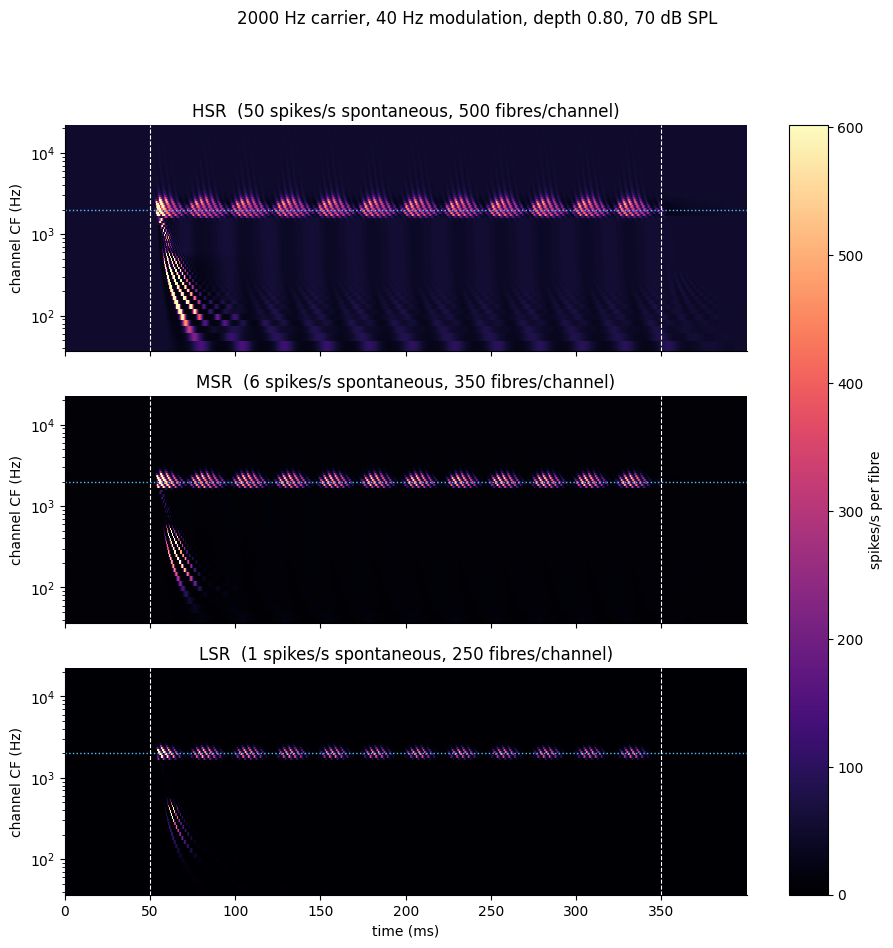

In [4]:
run = jax.jit(functools.partial(carfac_jax.run_segment, hypers=hypers))
out = run(stimulus[:, None], weights=weights, state=state)

print(f"synapse stage active: {hypers.ears[0].syn.do_syn}")
print(f"naps {np.asarray(out.naps).shape}  "
      f"naps_fibers {np.asarray(out.naps_fibers).shape}")

# Drop the single-ear axis, then scale to spikes/s per fibre.
fibers = np.squeeze(np.asarray(out.naps_fibers)) * FS / FIBER_COUNTS

assert fibers.ndim == 3 and fibers.shape[-1] == 3, fibers.shape

# CARFAC orders channels high to low; flip to ascending.
order = np.argsort(CHANNEL_CF)
cfs = CHANNEL_CF[order]
fibers = fibers[:, order, :]

for c, name in enumerate(CLASS_NAMES):
  r = fibers[:, :, c]
  tone_part = r[n_lead:n_lead + n_tone]
  print(f"{name}: peak {r.max():7.1f}  mean during tone "
        f"{tone_part.mean():6.2f} spikes/s  "
        f"({FIBER_COUNTS[c]:.0f} fibres/channel, "
        f"{SPONT_RATES[c]:.0f} spikes/s spontaneous)")

time_ms = 1000 * np.arange(stimulus.size) / FS
onset_ms = 1000 * LEAD_S
offset_ms = 1000 * (LEAD_S + TONE_S)
vmax = float(np.percentile(fibers, 99.9))

fig, axes = plt.subplots(3, 1, figsize=(11, 10), sharex=True)
for c, ax in enumerate(axes):
  mesh = ax.pcolormesh(time_ms, cfs, fibers[:, :, c].T, shading="auto",
                       cmap="magma", vmin=0, vmax=vmax)
  ax.set(yscale="log", ylabel="channel CF (Hz)",
         title=f"{CLASS_NAMES[c]}  "
               f"({SPONT_RATES[c]:.0f} spikes/s spontaneous, "
               f"{FIBER_COUNTS[c]:.0f} fibres/channel)")
  ax.axhline(CARRIER_HZ, color="#4fc3f7", lw=1, ls=":")
  for x in (onset_ms, offset_ms):
    ax.axvline(x, color="white", lw=0.8, ls="--")
  ax.spines[["top", "right"]].set_visible(False)

axes[-1].set_xlabel("time (ms)")
fig.suptitle(f"{CARRIER_HZ:.0f} Hz carrier, {MOD_HZ:.0f} Hz modulation, "
             f"depth {MOD_DEPTH:.2f}, {LEVEL_DB_SPL:.0f} dB SPL", y=0.995)
fig.colorbar(mesh, ax=axes, label="spikes/s per fibre")
plt.show()